# 02 — Training Detektor Plat YOLOv8n
**Proyek:** Smart Gate FT UNTIRTA — ALPR plat nomor Indonesia (YOLOv8n + PaddleOCR)

Masukan: `data/detect/` dan `plate.yaml` dari notebook 01.
Keluaran:
1. `models/yolov8n_plate_best.pt` — detektor plat terlatih.
2. `models/yolov8n_plate_openvino_640/` dan `..._416/` — versi OpenVINO untuk mini PC.
3. Metrik validasi dan test (mAP50, precision, recall).

**Runtime:** T4 GPU. Perkiraan training ±1–2 jam.

## 1. GPU, Drive, Ultralytics

In [2]:
!nvidia-smi
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/0-KEPSTON/model_alpr'

!pip install -q -U ultralytics
import ultralytics
ultralytics.checks()

Thu Nov 12 15:55:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.08                 Driver Version: 581.08         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1650      WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   54C    P8              2W /   50W |       0MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

ModuleNotFoundError: No module named 'google.colab'

## 2. Salin dataset ke disk lokal Colab
Membaca ribuan gambar langsung dari Drive saat training sangat lambat, jadi dataset disalin sekali ke `/content/detect`.
Hasil training tetap disimpan ke Drive.

In [ ]:
import shutil
from pathlib import Path

LOCAL = Path('/content/detect')
if not LOCAL.exists():
    shutil.copytree(f'{ROOT}/data/detect', LOCAL)
for s in ['train', 'valid', 'test']:
    print(s, len(list((LOCAL / s / 'images').glob('*'))), 'gambar')

DATA_YAML = '/content/plate_local.yaml'
Path(DATA_YAML).write_text(f'''path: {LOCAL}
train: train/images
val: valid/images
test: test/images

names:
  0: plate
''')
print(open(DATA_YAML).read())

## 3. Training
- `yolov8n.pt` pretrained COCO sebagai titik awal (transfer learning).
- `imgsz=640`, `epochs=100`, `batch=16`, `patience=20` (berhenti otomatis bila 20 epoch tidak membaik).
- Augmentasi bawaan YOLOv8 (mosaic, HSV, skala, translasi, flip) aktif otomatis.

In [ ]:
from ultralytics import YOLO

RUN = f'{ROOT}/models/runs/yolov8n_plate'
model = YOLO('yolov8n.pt')
results = model.train(data=DATA_YAML, imgsz=640, epochs=200, batch=32, patience=20, seed=42,
                      project=f'{ROOT}/models/runs', name='yolov8n_plate', exist_ok=True, plots=True)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/plate_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_plate, nbs=64, nms=None, opset=None, optimize=False, o

### Kalau sesi terputus: jalankan sel 1–2, lalu sel ini (jangan ulangi sel training)

In [ ]:
from ultralytics import YOLO
RUN = f'{ROOT}/models/runs/yolov8n_plate'
model = YOLO(f'{RUN}/weights/last.pt')
results = model.train(resume=True)

## 4. Grafik training
Loss turun lalu mendatar dan mAP naik lalu stabil = sehat. Loss validasi naik sementara loss train turun = overfitting.

results.png


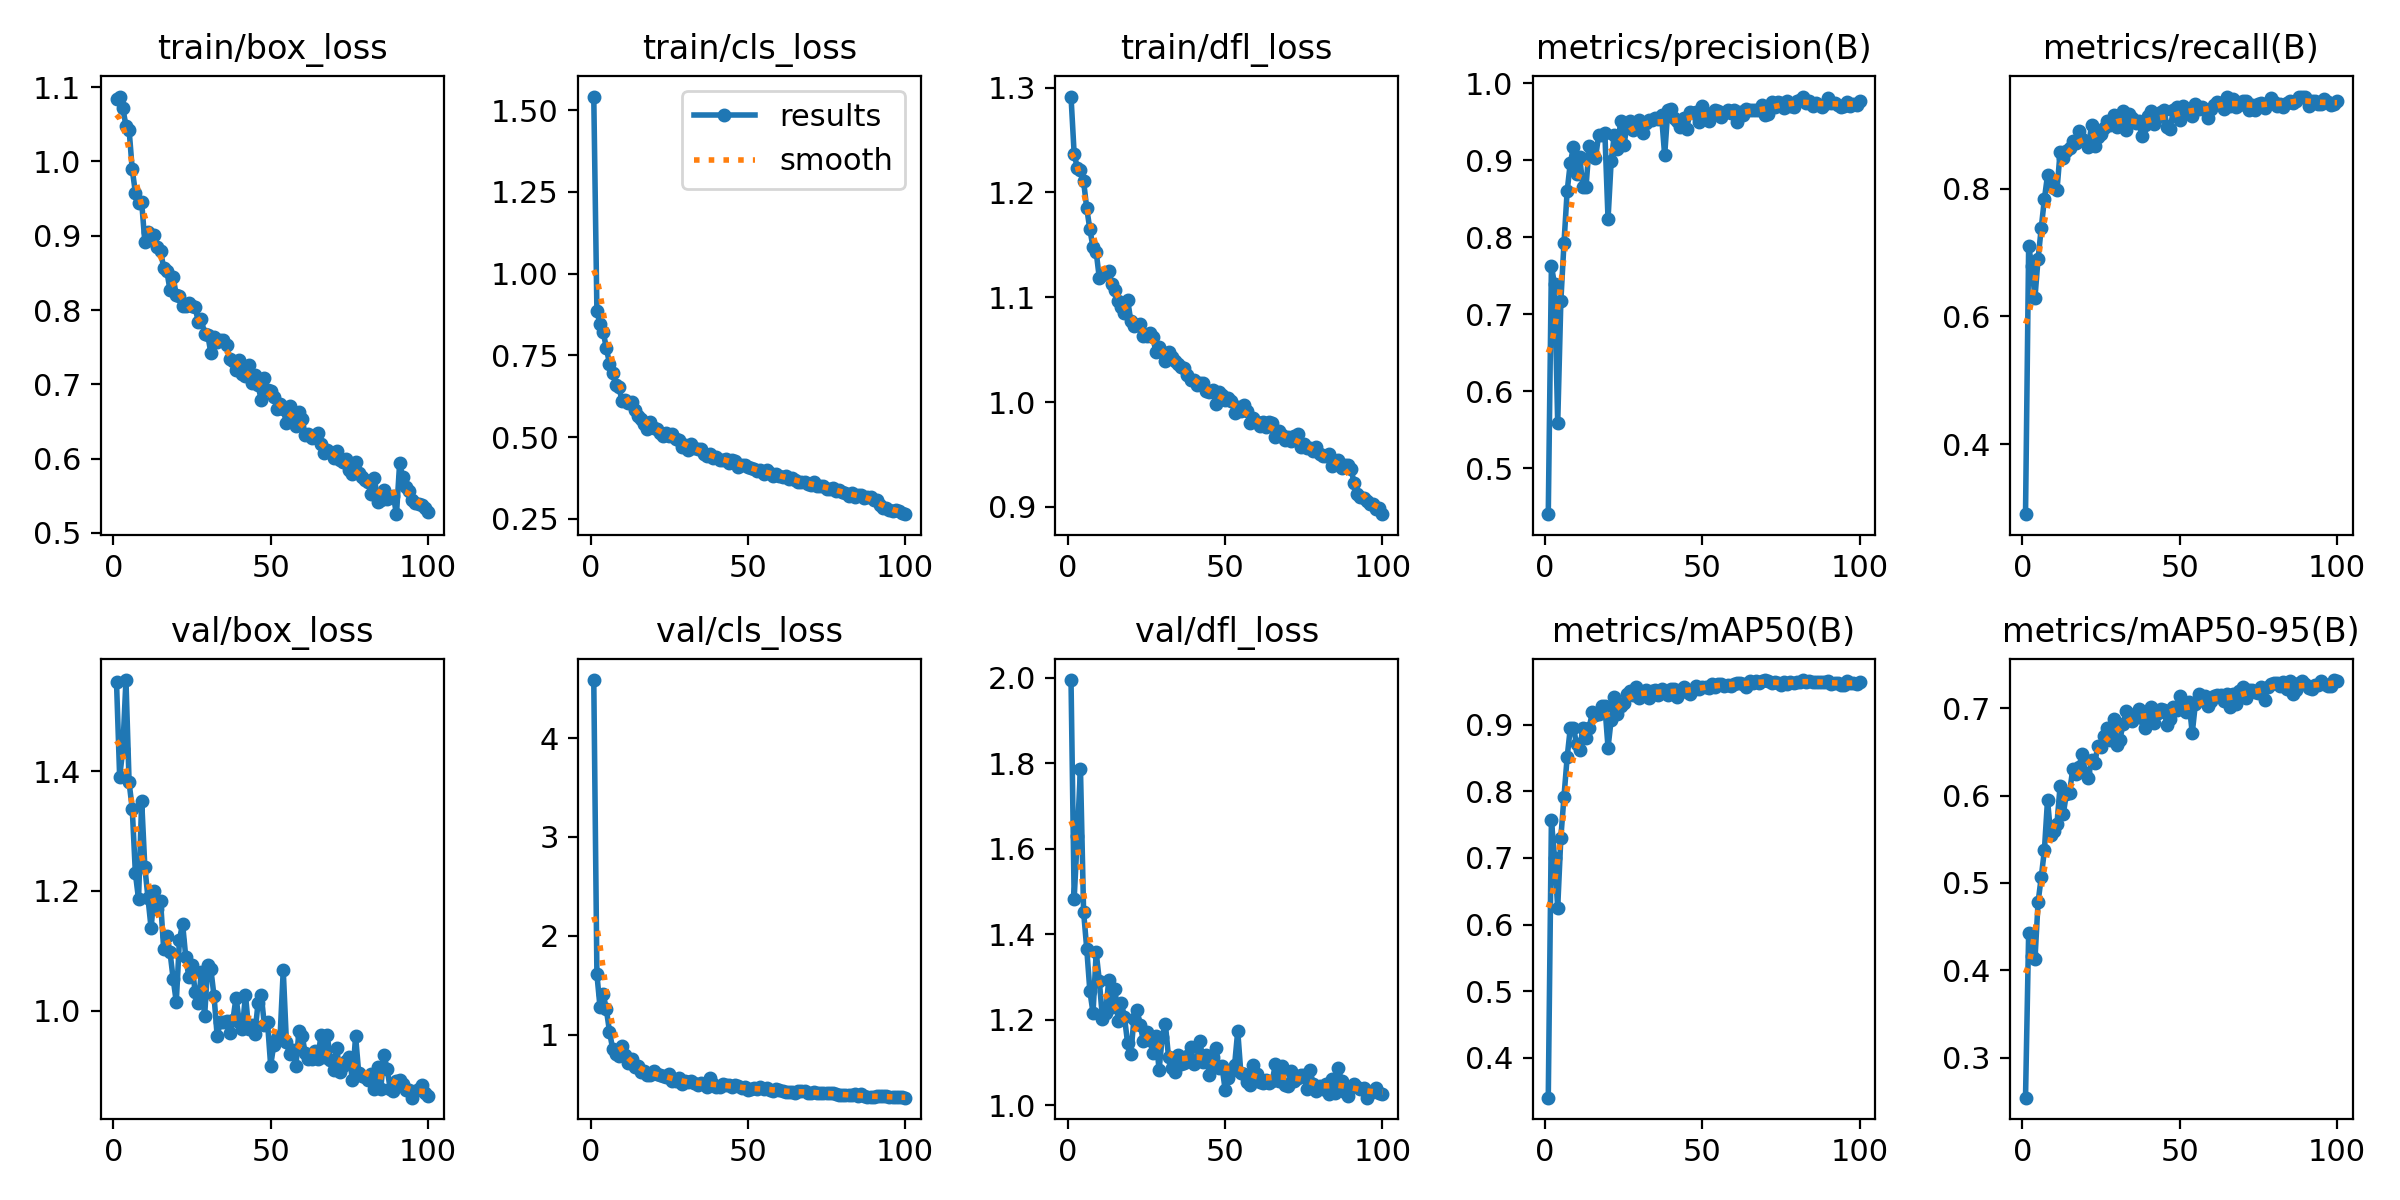

confusion_matrix.png


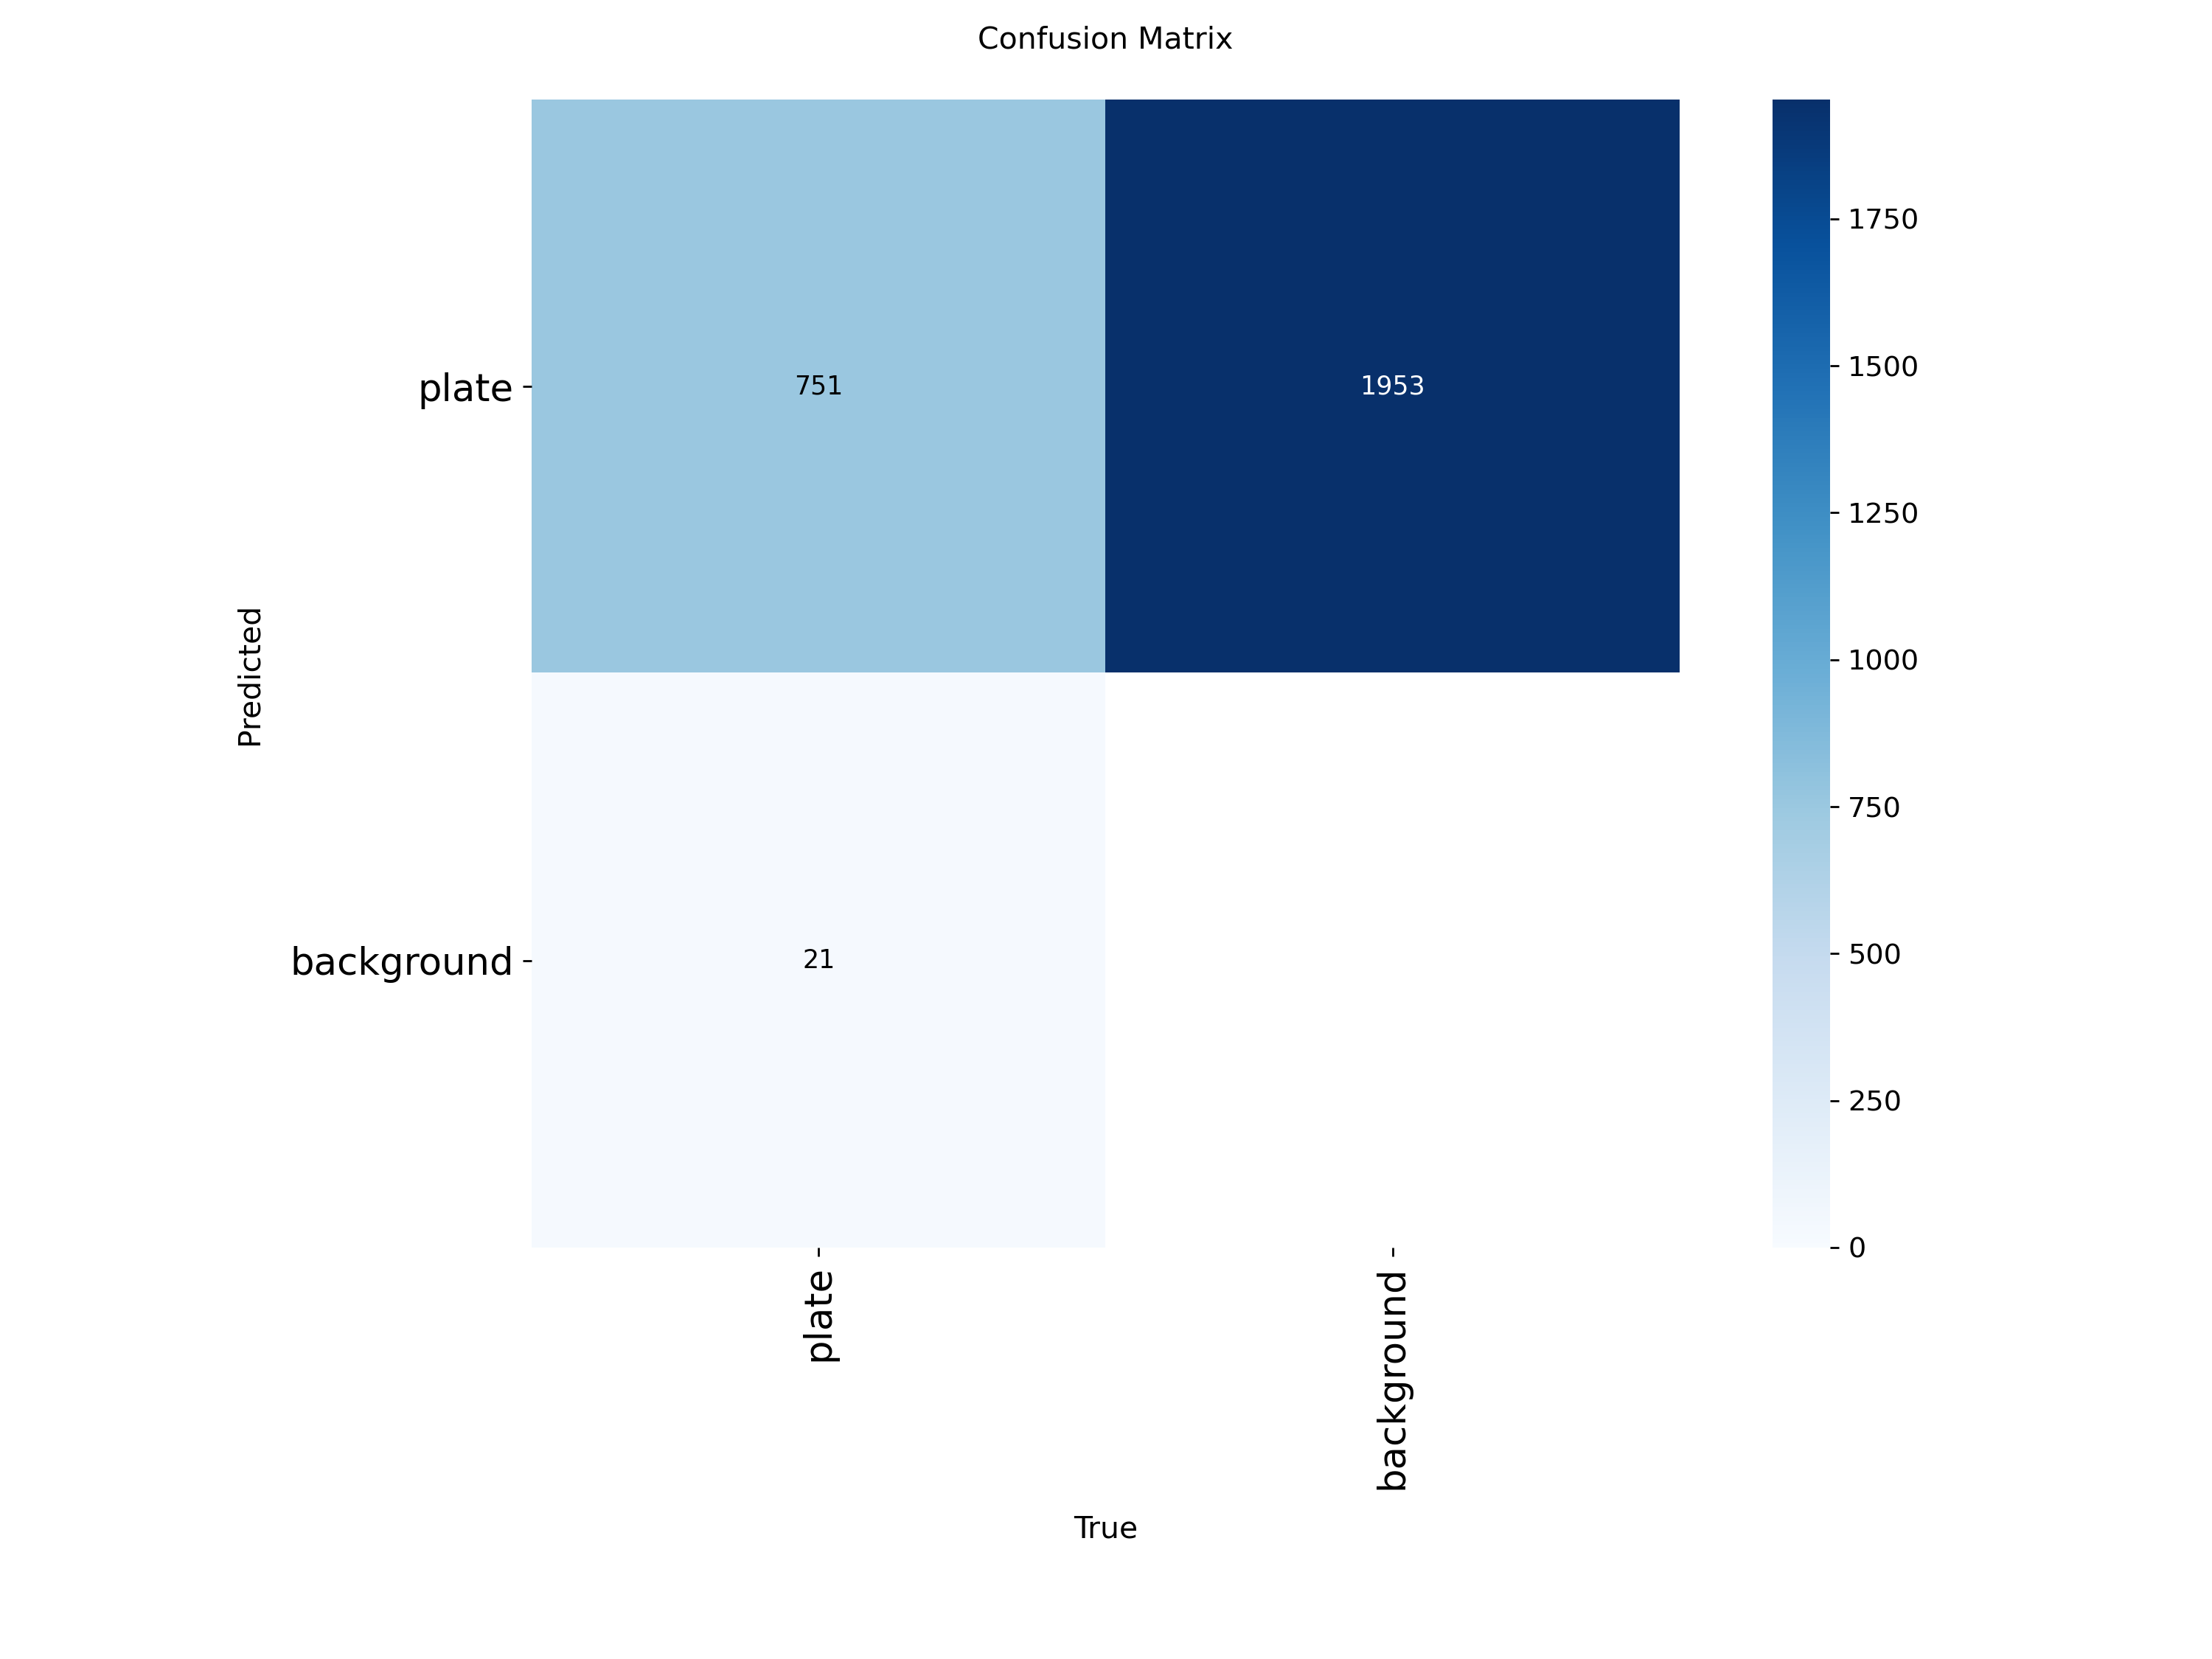

BoxPR_curve.png


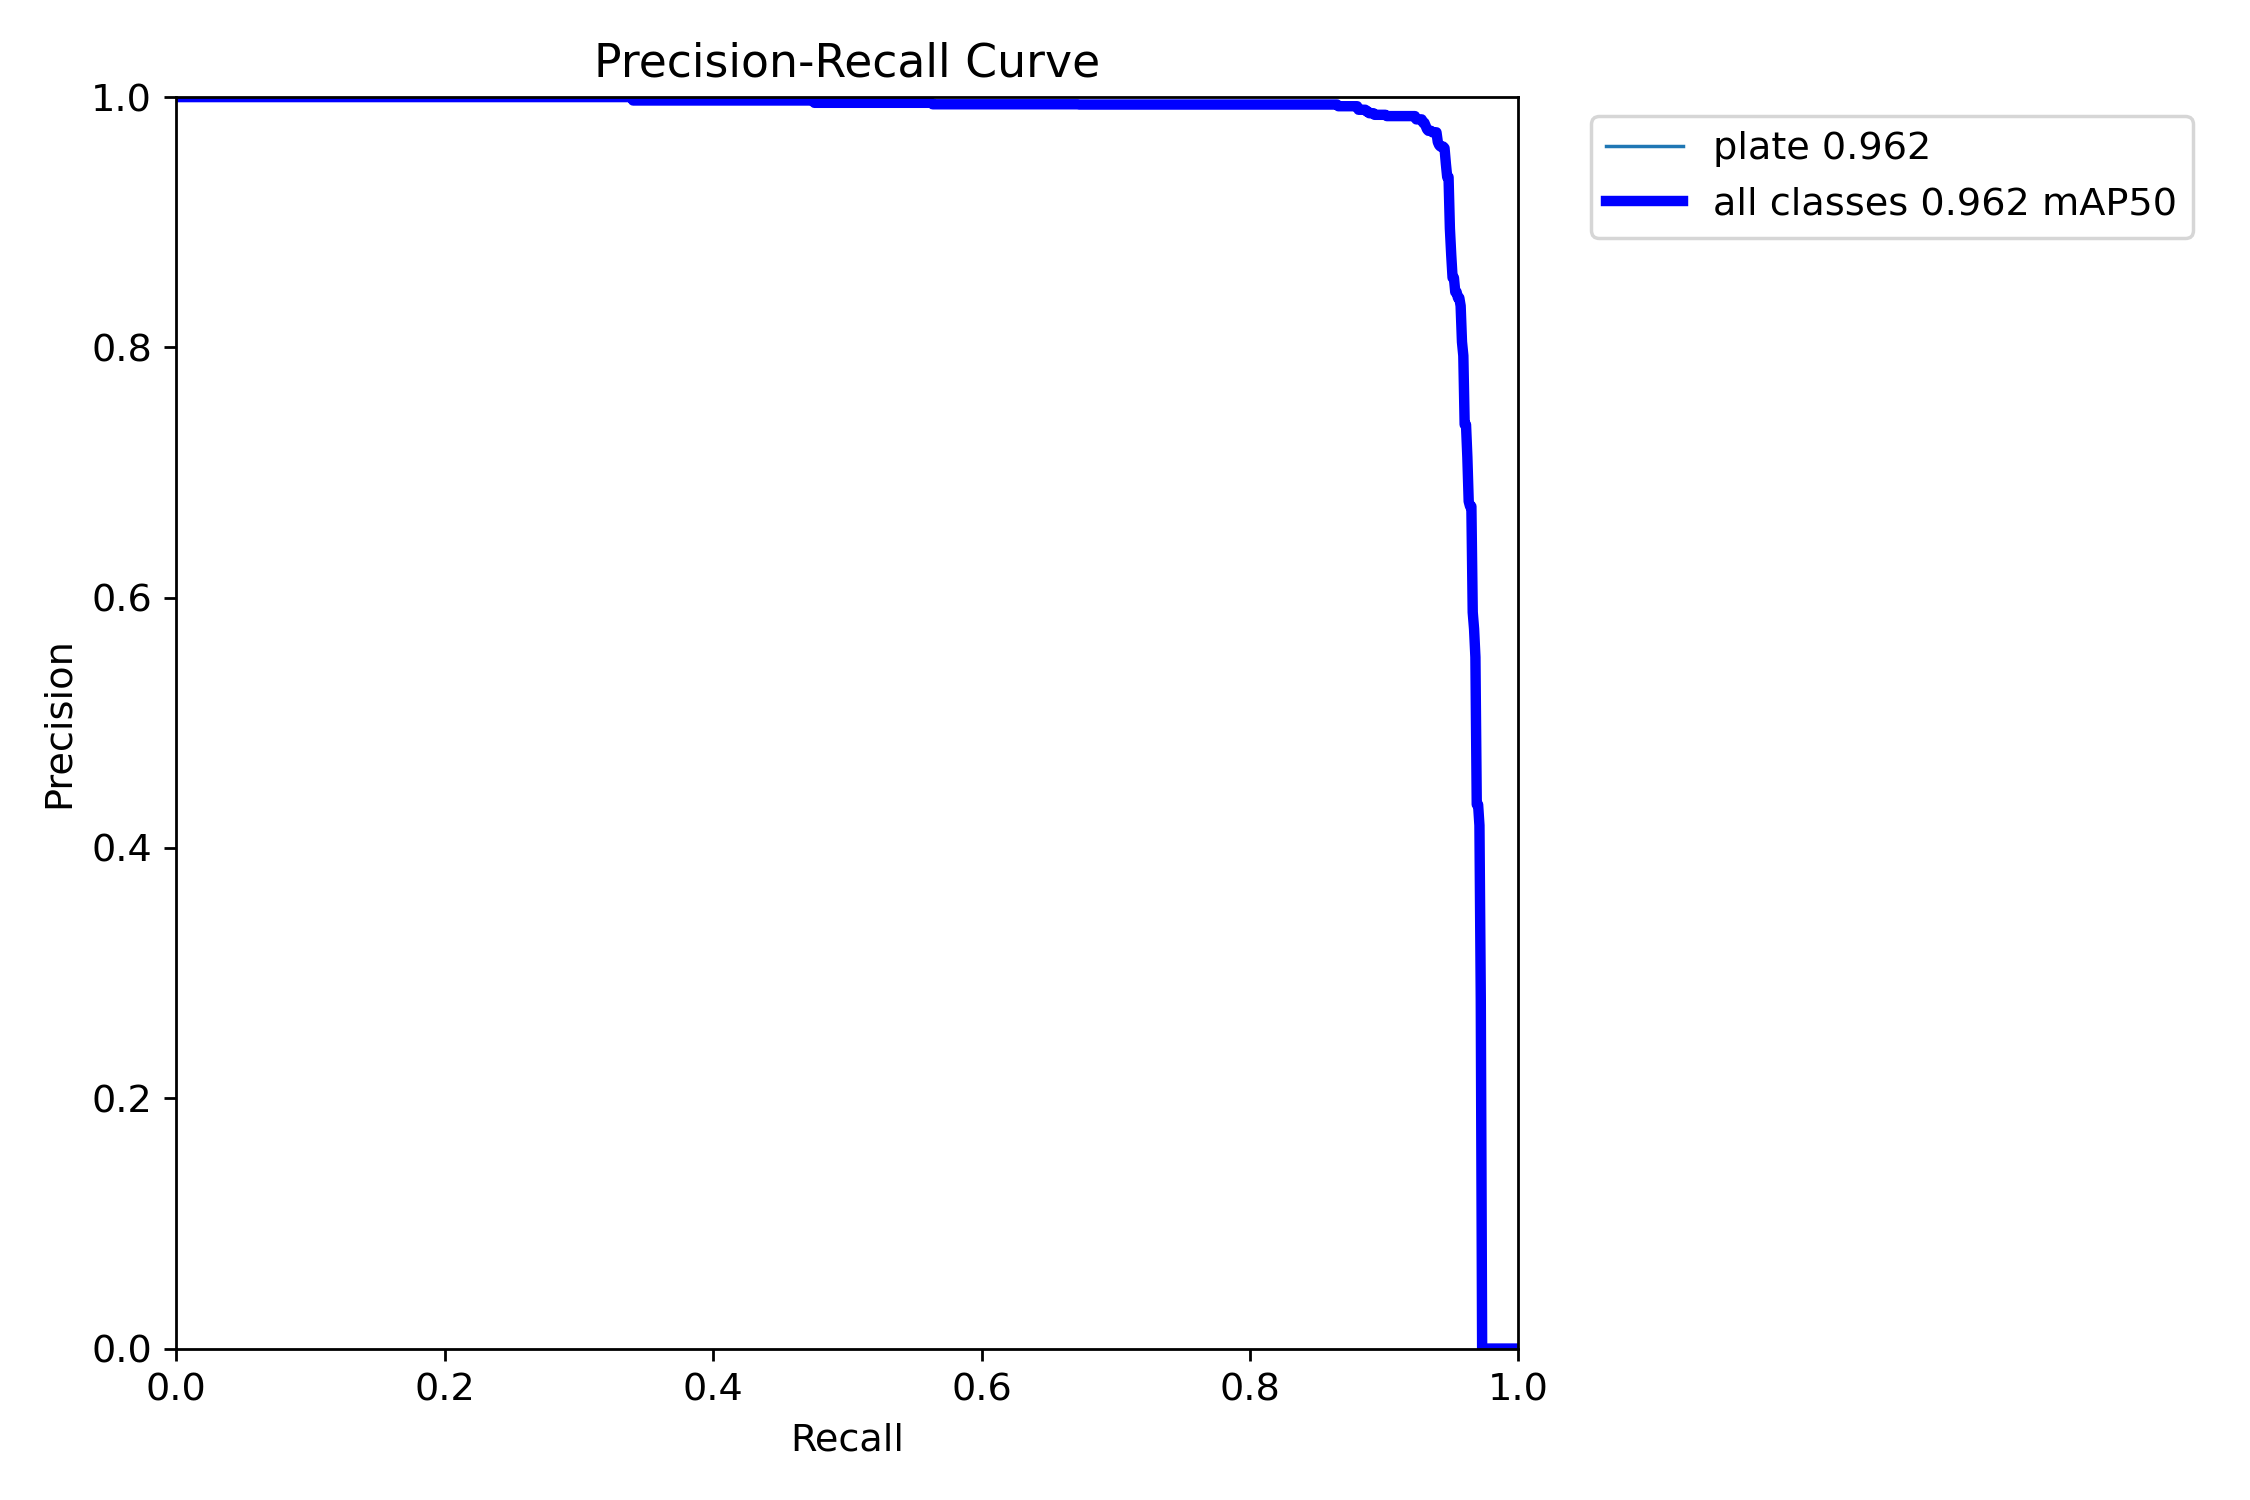

In [ ]:
from IPython.display import Image, display
RUN = f'{ROOT}/models/runs/yolov8n_plate'
for f in ['results.png', 'confusion_matrix.png', 'BoxPR_curve.png', 'PR_curve.png']:
    p = Path(RUN) / f
    if p.exists():
        print(f); display(Image(filename=str(p), width=900))

## 5. Evaluasi validasi dan test
Target: **mAP50 ≥ 0,95**, **recall ≥ 0,97**. Angka **test** yang dipakai di laporan.

In [ ]:
best = YOLO(f'{RUN}/weights/best.pt')
for split in ['val', 'test']:
    m = best.val(data=DATA_YAML, split=split, imgsz=640, verbose=False,
                 project=f'{ROOT}/eval', name=f'yolov8n_{split}', exist_ok=True)
    print(f'{split:4s} | mAP50 = {m.box.map50:.3f} | mAP50-95 = {m.box.map:.3f} | '
          f'precision = {m.box.mp:.3f} | recall = {m.box.mr:.3f}')

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1615.7±663.2 MB/s, size: 56.2 KB)
val: Scanning /content/detect/valid/labels.cache... 622 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 622/622 200.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 9.8it/s 4.0s
                   all        622        772      0.974      0.934      0.961      0.733
Speed: 0.5ms preprocess, 1.6ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/drive/MyDrive/0-KEPSTON/model_alpr/eval/yolov8n_val
val  | mAP50 = 0.961 | mAP50-95 = 0.733 | precision = 0.974 | recall = 0.934
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
v

## 6. Contoh deteksi pada gambar test

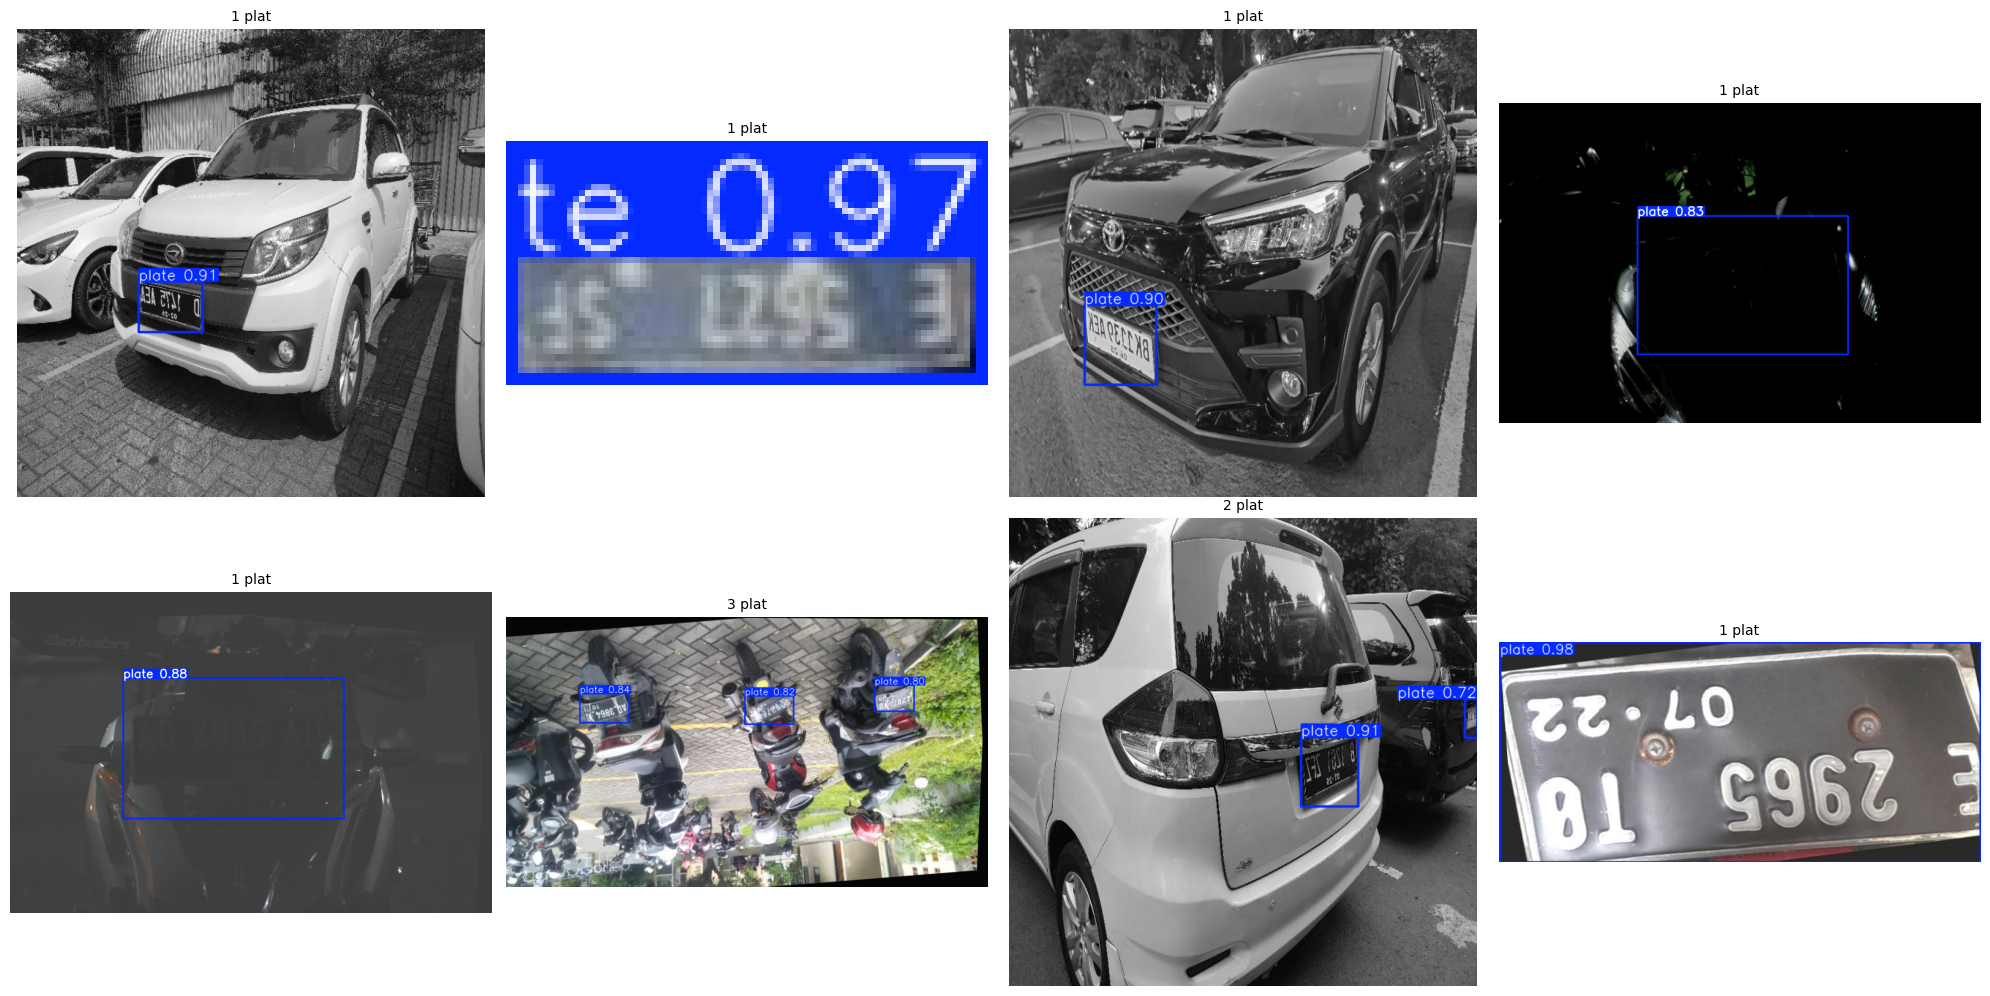

In [ ]:
import random
import matplotlib.pyplot as plt
imgs = random.sample(list((LOCAL / 'test' / 'images').glob('*')), 8)
preds = best.predict(imgs, imgsz=640, conf=0.5, verbose=False)
plt.figure(figsize=(20, 10))
for i, p in enumerate(preds):
    plt.subplot(2, 4, i + 1); plt.imshow(p.plot()[:, :, ::-1]); plt.axis('off')
    plt.title(f'{len(p.boxes)} plat', fontsize=10)
plt.tight_layout(); plt.show()

## 7. Simpan bobot final dan ekspor OpenVINO
Mini PC (Beelink T4 Pro, Celeron N3350) menjalankan model lewat **OpenVINO** tanpa PyTorch.
Diekspor dua ukuran input: **640** (akurasi penuh) dan **416** (lebih cepat). Keduanya dibandingkan di notebook 05.

In [ ]:
import os
FINAL = f'{ROOT}/models/yolov8n_plate_best.pt'
shutil.copy(f'{RUN}/weights/best.pt', FINAL)
print('Tersimpan:', FINAL)

for sz in [640, 416]:
    exp_dir = YOLO(FINAL).export(format='openvino', imgsz=sz, half=False)
    dst = f'{ROOT}/models/yolov8n_plate_openvino_{sz}'
    if os.path.exists(dst):
        shutil.rmtree(dst)
    shutil.copytree(exp_dir, dst)
    print('OpenVINO', sz, '->', dst, os.listdir(dst))

Tersimpan: /content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_best.pt
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)
requirements: Ultralytics requirement ['openvino>=2024.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 3 packages in 175ms
Prepared 2 packages in 579ms
Installed 2 packages in 17ms
 + openvino==2026.4.1
 + openvino-telemetry==2025.2.0

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requi

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


OpenVINO: export success ✅ 3.2s, saved as '/content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_best_openvino_model/' (12.3 MB)

Export complete (3.4s)
Results saved to /content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_best_openvino_model
Predict:         yolo predict task=detect model=/content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_best_openvino_model/ imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_best_openvino_model/ imgsz=640 data=/content/plate_local.yaml 
Visualize:       https://netron.app
OpenVINO 640 -> /content/drive/MyDrive/0-KEPSTON/model_alpr/models/yolov8n_plate_openvino_640 ['yolov8n_plate_best.bin', 'yolov8n_plate_best.xml', 'metadata.yaml']
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,132

---
### Checklist 02
- [ ] mAP50 test ≥ 0,95 dan recall test ≥ 0,97 (catat angkanya untuk laporan)
- [ ] `models/yolov8n_plate_best.pt` ada di Drive
- [ ] `models/yolov8n_plate_openvino_640/` dan `_416/` ada di Drive

**Berikutnya:** `03_dataset_ocr.ipynb`